<a href="https://colab.research.google.com/github/CauaMaia/processamento_de_imagens/blob/main/trabalhos/trabalho_portfolio_2/filtros_lineares_nao_lineares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Filtros Lineares e Não-Lineares

Implementação manual (sem funções nativas do OpenCV, incluindo `filter2D`) dos filtros:

* **Média** (linear) — aplicado via convolução manual
* **Mediana** (não-linear)
* **Moda** (não-linear)
* **Máxima** (não-linear)

Imagem de exemplo: `skimage.data.camera()` (escala de cinza).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

Matplotlib is building the font cache; this may take a moment.


## Funções auxiliares

* `adicionar_padding`: replica as bordas da imagem para que a imagem filtrada tenha o mesmo tamanho da original.
* `convolucao`: convolução 2D manual (o kernel é espelhado, conforme a definição de convolução).
* `filtro_janela`: percorre a imagem com uma janela deslizante e aplica uma função sobre a vizinhança — base dos filtros não-lineares.

In [2]:
def adicionar_padding(img, pad):
    """Adiciona `pad` pixels em cada borda, replicando os valores da borda."""
    h, w = img.shape
    saida = np.zeros((h + 2 * pad, w + 2 * pad), dtype=img.dtype)
    saida[pad:pad + h, pad:pad + w] = img
    # bordas superior e inferior
    saida[:pad, pad:pad + w] = img[0, :]
    saida[pad + h:, pad:pad + w] = img[-1, :]
    # bordas esquerda e direita (inclui os cantos)
    saida[:, :pad] = saida[:, pad:pad + 1]
    saida[:, pad + w:] = saida[:, pad + w - 1:pad + w]
    return saida


def convolucao(img, kernel):
    """Convolução 2D manual entre uma imagem em escala de cinza e um kernel quadrado de tamanho ímpar."""
    k = kernel.shape[0]
    pad = k // 2
    kernel_espelhado = kernel[::-1, ::-1]  # convolução: kernel rotacionado em 180°
    img_pad = adicionar_padding(img.astype(np.float64), pad)

    h, w = img.shape
    saida = np.zeros((h, w), dtype=np.float64)
    for i in range(h):
        for j in range(w):
            regiao = img_pad[i:i + k, j:j + k]
            saida[i, j] = np.sum(regiao * kernel_espelhado)

    return np.clip(saida, 0, 255).astype(np.uint8)


def filtro_janela(img, tamanho, funcao):
    """Aplica `funcao` sobre cada vizinhança tamanho x tamanho da imagem (janela deslizante)."""
    pad = tamanho // 2
    img_pad = adicionar_padding(img, pad)

    h, w = img.shape
    saida = np.zeros((h, w), dtype=img.dtype)
    for i in range(h):
        for j in range(w):
            regiao = img_pad[i:i + tamanho, j:j + tamanho]
            saida[i, j] = funcao(regiao)
    return saida


def implot(img, img_filt, nomefiltro, tamanho):
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title('Imagem Original')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_filt, cmap='gray', vmin=0, vmax=255)
    plt.title(f'Filtro {nomefiltro} {tamanho}x{tamanho}')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

## Filtros

In [3]:
def filtro_media(img, tamanho=3):
    """Filtro da média (linear): convolução com kernel de pesos iguais que somam 1."""
    kernel = np.ones((tamanho, tamanho), dtype=np.float64)
    kernel = kernel / np.sum(kernel)
    return convolucao(img, kernel)


def filtro_mediana(img, tamanho=3):
    """Filtro da mediana: valor central da vizinhança ordenada."""
    def mediana(regiao):
        valores = np.sort(regiao.ravel())
        return valores[len(valores) // 2]
    return filtro_janela(img, tamanho, mediana)


def filtro_moda(img, tamanho=3):
    """Filtro da moda: valor mais frequente da vizinhança (em empate, o menor valor)."""
    def moda(regiao):
        contagem = np.bincount(regiao.ravel(), minlength=256)
        return np.argmax(contagem)
    return filtro_janela(img, tamanho, moda)


def filtro_maxima(img, tamanho=3):
    """Filtro da máxima: maior valor da vizinhança."""
    def maxima(regiao):
        maior = regiao[0, 0]
        for valor in regiao.ravel():
            if valor > maior:
                maior = valor
        return maior
    return filtro_janela(img, tamanho, maxima)

## Imagem de exemplo

In [4]:
img = data.camera()  # já em escala de cinza (uint8)
print(img.shape, img.dtype)
TAMANHO = 5

(512, 512) uint8


### Média

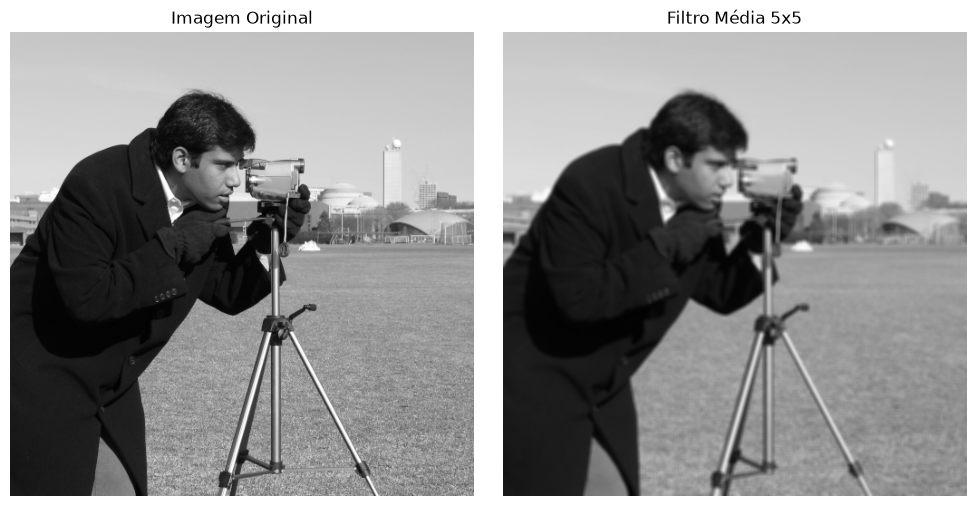

In [5]:
img_media = filtro_media(img, TAMANHO)
implot(img, img_media, 'Média', TAMANHO)

### Mediana

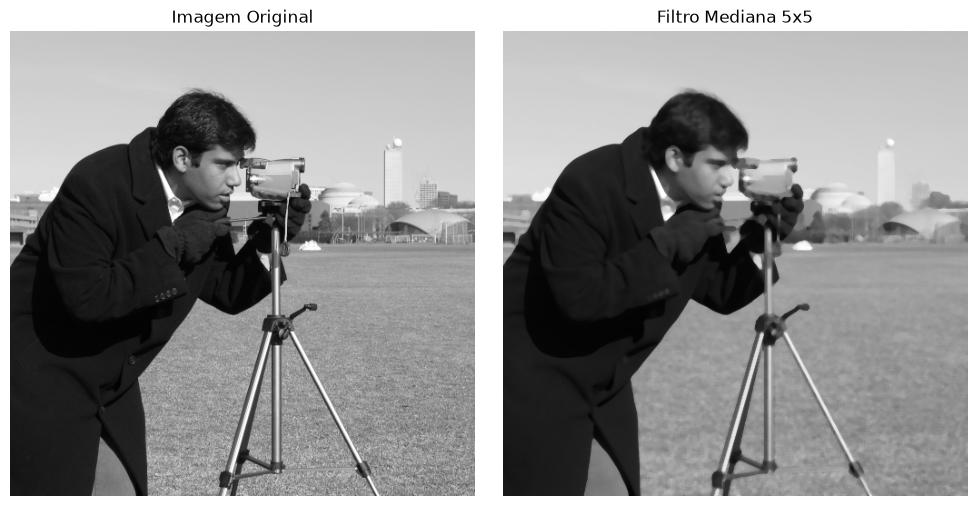

In [6]:
img_mediana = filtro_mediana(img, TAMANHO)
implot(img, img_mediana, 'Mediana', TAMANHO)

### Moda

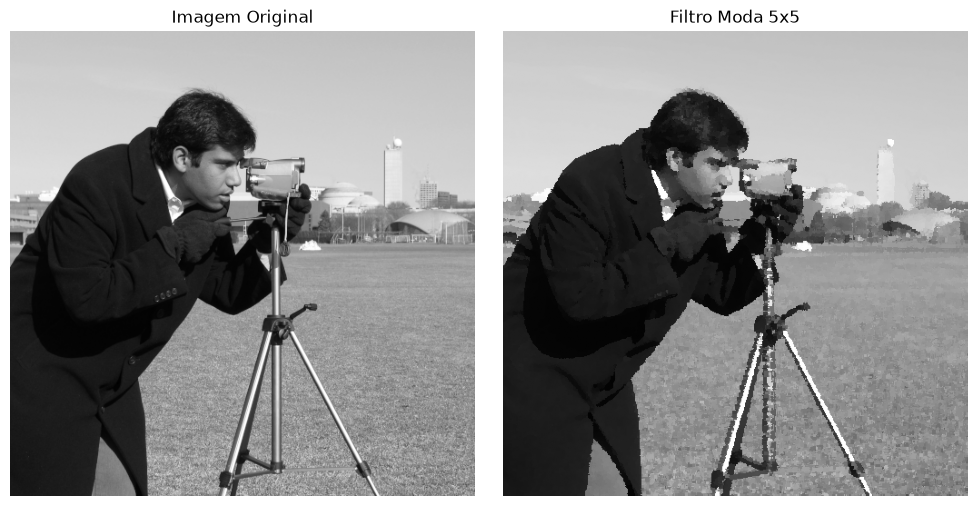

In [7]:
img_moda = filtro_moda(img, TAMANHO)
implot(img, img_moda, 'Moda', TAMANHO)

### Máxima

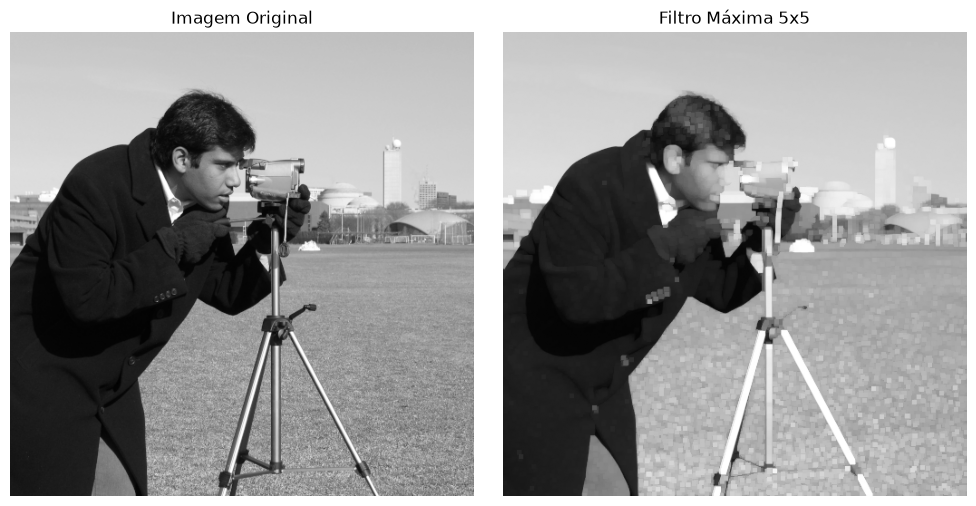

In [8]:
img_maxima = filtro_maxima(img, TAMANHO)
implot(img, img_maxima, 'Máxima', TAMANHO)

## Extra: ruído sal e pimenta

Os filtros não-lineares mostram sua vantagem em ruído impulsivo: a mediana remove o ruído preservando bordas, enquanto a média apenas o espalha.

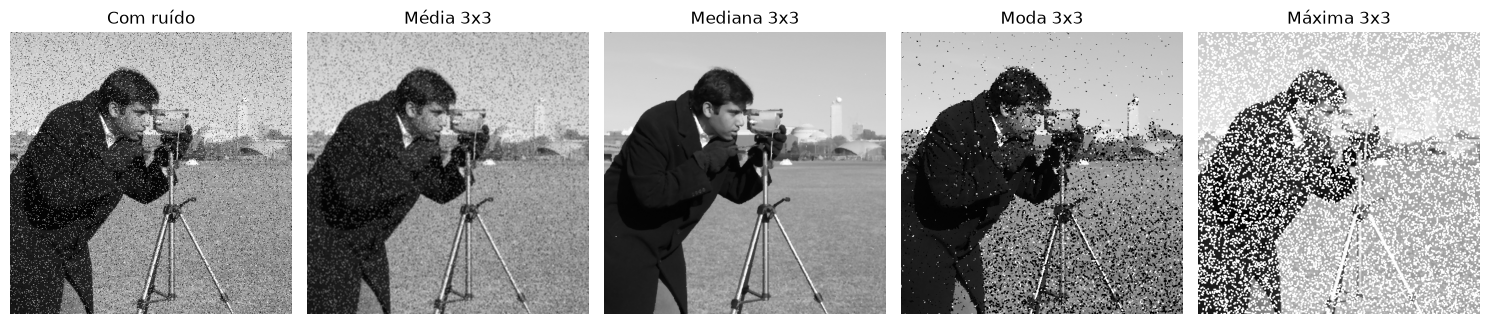

In [9]:
rng = np.random.default_rng(0)
img_ruido = img.copy()
mascara = rng.random(img.shape)
img_ruido[mascara < 0.05] = 0
img_ruido[mascara > 0.95] = 255

filtros = [('Média', filtro_media), ('Mediana', filtro_mediana),
           ('Moda', filtro_moda), ('Máxima', filtro_maxima)]

plt.figure(figsize=(15, 3.5))
plt.subplot(1, 5, 1)
plt.imshow(img_ruido, cmap='gray', vmin=0, vmax=255)
plt.title('Com ruído')
plt.axis('off')
for idx, (nome, filtro) in enumerate(filtros, start=2):
    plt.subplot(1, 5, idx)
    plt.imshow(filtro(img_ruido, 3), cmap='gray', vmin=0, vmax=255)
    plt.title(f'{nome} 3x3')
    plt.axis('off')
plt.tight_layout()
plt.show()